# From features to predictions

Run the real model functions on a bounded chronological development example.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

Persistence carries forward the last known report. The daily calendar baseline uses the report seven calendar days earlier when available. The moving average smooths the last seven observations. Ridge estimates a regularized linear adjustment, and histogram gradient boosting estimates nonlinear adjustments with shallow trees.

,rows,mae,rmse,smape_pct
persistence,75.0,68.00,175.50,3.47
seasonal_naive_7d,75.0,138.67,264.32,6.88
moving_average_7obs,75.0,119.24,224.54,5.98
ridge,75.0,88.43,178.53,4.41
hist_gradient_boosting,75.0,111.76,185.10,5.49


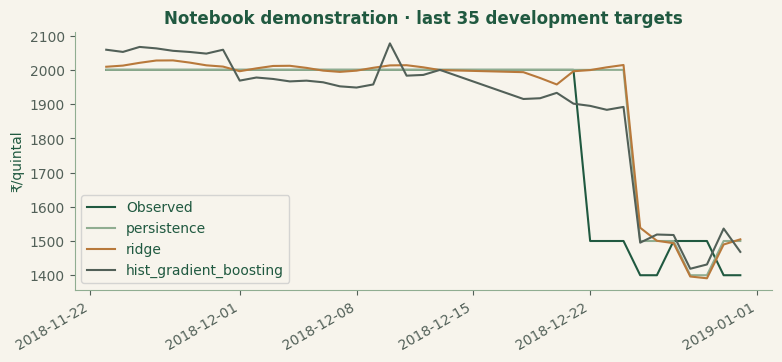

In [2]:
from Code.daily.forecast import baselines, features, fit_models, learned_predictions, metrics
from Code.daily.policy import IST

history = development_market().tail(420)
samples = []
for row in history.iloc[45:].itertuples():
    vector, _, known = features(history, row.date, row.date.tz_localize(IST) + pd.Timedelta(hours=8))
    if vector is not None:
        samples.append((row.date, row.price, vector, baselines(known, row.date)))
dates, y, x, benchmarks = zip(*samples)
x, y = np.stack(x), np.asarray(y)
benchmark = pd.DataFrame(benchmarks, index=pd.DatetimeIndex(dates))
last = benchmark.persistence.to_numpy()
split = int(.8 * len(y))
assert dates[split-1] < dates[split]
models = fit_models(x[:split], y[:split] / last[:split] - 1)
pred = benchmark.iloc[split:].assign(**learned_predictions(models, x[split:], last[split:]))
display(pd.DataFrame({name: metrics(y[split:], pred[name]) for name in pred}).T.round(2))
pred.assign(Observed=y[split:])[["Observed", "persistence", "ridge", "hist_gradient_boosting"]].tail(35).plot(
    title="Notebook demonstration · last 35 development targets", ylabel="₹/quintal")
plt.show()

This single-market exercise uses pre-2019 observations and the archive availability convention. It runs a small fit and reports demonstration errors. Notebook 08 reads the separately saved experiment results.

**Takeaway** · The workflow trains candidates on past observations and benchmarks them against a simple persistence forecast.

**Next** · Use archived results to assess the actual model decisions in Notebook 08.